# Dengue en Loreto (2000–2024)
## Notebook 04 · Visualización

**Entrada:** `data/dengue_loreto.db`, la base de datos SQLite generada en `03_sql.ipynb` (tablas `casos`, `poblacion` y `poblacion_edad`).

**Qué hace este notebook:** convierte los hallazgos principales del análisis en gráficos. Cada gráfico responde a una parte de la pregunta: cuándo, dónde y a quiénes afecta más el dengue en Loreto.

**Contenido**
1. Preparación
2. Casos por año
3. Estacionalidad
4. Incidencia por distrito
5. Incidencia por grupo de edad

**Resultado:** imágenes PNG en la carpeta `figures/`, para usarlas en el README.

---
## 1. Preparación

Los datos se leen directamente de la base de datos SQLite, con la misma función `consulta` del notebook 03. Se define un estilo común para todos los gráficos: sin bordes superior y derecho, gris para el contexto y un solo color para destacar.

In [2]:
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conexion = sqlite3.connect("../data/dengue_loreto.db")

def consulta(sql):
    """Ejecuta una consulta SQL y devuelve el resultado como DataFrame."""
    return pd.read_sql(sql, conexion)

# Carpeta para guardar los gráficos
os.makedirs("../figures", exist_ok=True)

# Estilo común para todos los gráficos
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

COLOR_BASE = "#9CA3AF"       # gris: contexto
COLOR_DESTACADO = "#B91C1C"  # rojo: lo que queremos mostrar
FUENTE = "Fuente: MINSA, vigilancia epidemiológica de dengue (Plataforma Nacional de Datos Abiertos)."

---
## 2. Casos por año

**Mensaje:** 2011 fue la mayor epidemia del periodo, con más del doble de casos que cualquier otro año. Se usan barras porque cada año es un valor separado, y solo 2011 va en color.

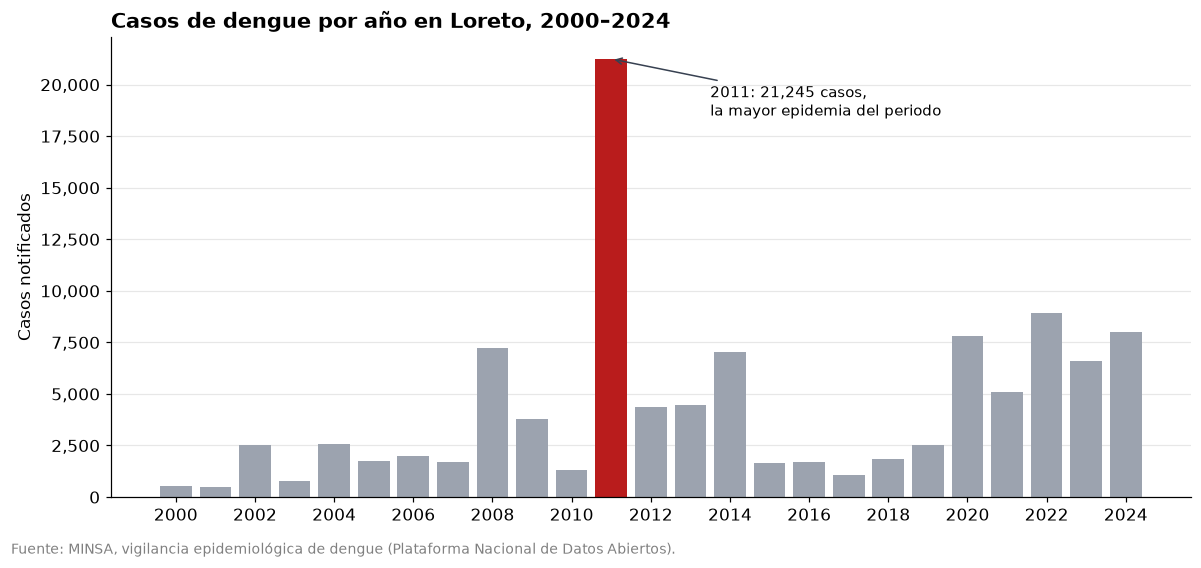

In [3]:
por_anio = consulta("""
SELECT ano, COUNT(*) AS casos
FROM casos
GROUP BY ano
ORDER BY ano
""")

# Un color por barra: rojo para 2011, gris para el resto
colores = [COLOR_DESTACADO if anio == 2011 else COLOR_BASE for anio in por_anio["ano"]]

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(por_anio["ano"], por_anio["casos"], color=colores)

# Nota con flecha sobre el pico
ax.annotate(
    "2011: 21,245 casos,\nla mayor epidemia del periodo",
    xy=(2011, 21245),        # punto al que apunta la flecha
    xytext=(2013.5, 18500),  # dónde va el texto
    arrowprops=dict(arrowstyle="->", color="#374151"),
    fontsize=10,
)

ax.set_title("Casos de dengue por año en Loreto, 2000–2024", loc="left", fontsize=14, fontweight="bold")
ax.set_ylabel("Casos notificados")
ax.set_xticks(por_anio["ano"][::2])   # un año sí y otro no, para que no se amontonen
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)                # la cuadrícula queda detrás de las barras

fig.text(0.01, -0.02, FUENTE, fontsize=9, color="gray")
plt.tight_layout()
fig.savefig("../figures/01_casos_por_anio.png", dpi=150, bbox_inches="tight")
plt.show()

> 🔎 **Qué muestra el gráfico:**
> - **2011 fue la mayor epidemia del periodo:** 21,245 casos, 2.4 veces más que el segundo año (2022, con 8,926).
> - **Desde 2020, los casos se mantienen altos todos los años:** ningún año baja de 5,000 casos (promedio de unos 7,280), frente a un promedio de unos 1,760 en 2015–2019. Es el cambio más importante para el presente.
> - **2023 y 2024**, años récord a nivel nacional, fueron en Loreto años altos pero no excepcionales: 31% y 38% del máximo de 2011.

---
## 3. Estacionalidad

**Mensaje:** todos los años, el dengue se concentra entre noviembre y abril.

Cada fila es un año y cada columna una semana epidemiológica; el color indica qué porcentaje de los casos de ese año ocurrió en esa semana. Se usan **porcentajes por año** y no casos, por la misma razón que en la sección 8.2 del notebook 03: con casos absolutos, 2011 ocuparía todo el color y los demás años se verían vacíos.

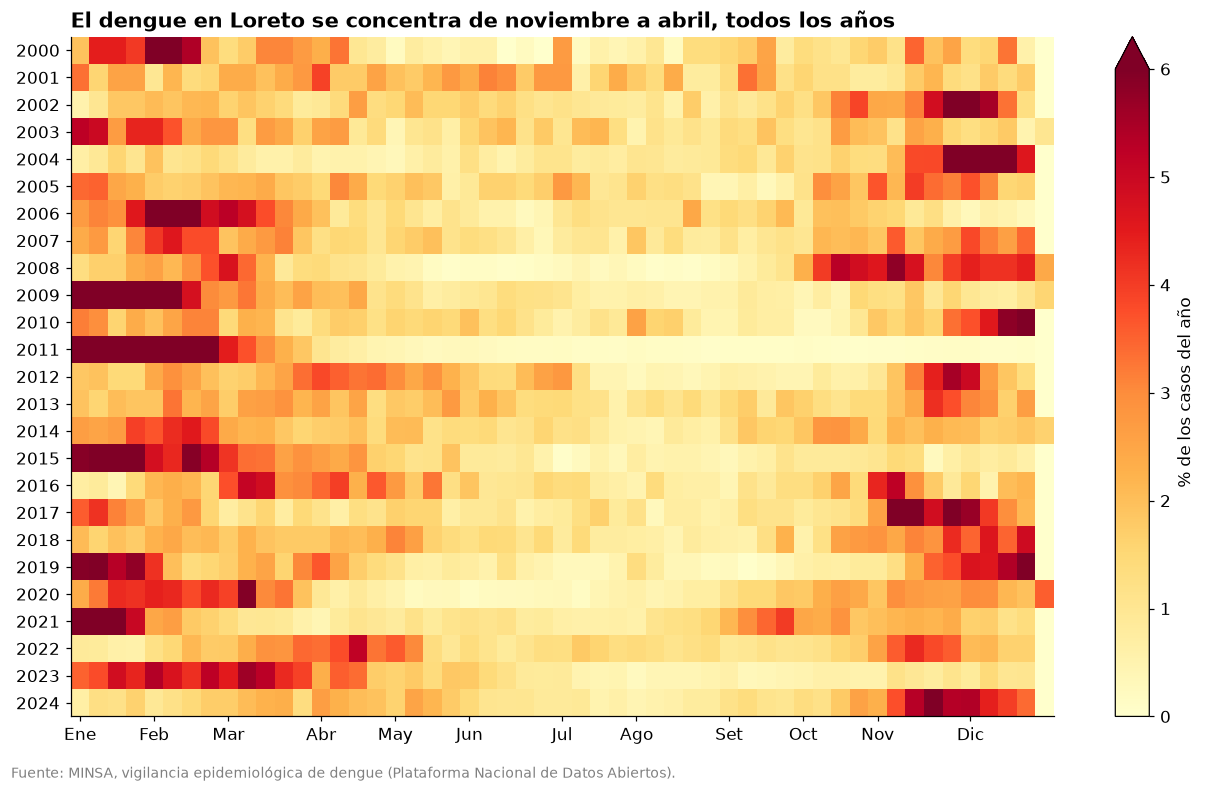

In [4]:
semanal = consulta("""
WITH semanal AS (
    SELECT ano, semana, COUNT(*) AS casos
    FROM casos
    GROUP BY ano, semana
)
SELECT
    ano,
    semana,
    casos * 100.0 / SUM(casos) OVER (PARTITION BY ano) AS pct
FROM semanal
""")

# Tabla dinámica: filas = años, columnas = semanas, valores = porcentaje
tabla = semanal.pivot(index="ano", columns="semana", values="pct").fillna(0)

fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(tabla, aspect="auto", cmap="YlOrRd", vmax=6)

# Eje Y: todos los años
ax.set_yticks(range(len(tabla.index)))
ax.set_yticklabels(tabla.index)

# Eje X: el nombre del mes en la semana en que empieza (aproximado)
semanas_mes = [1, 5, 9, 14, 18, 22, 27, 31, 36, 40, 44, 49]
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Set", "Oct", "Nov", "Dic"]
ax.set_xticks([s - 1 for s in semanas_mes])   # la columna de la semana 1 está en la posición 0
ax.set_xticklabels(meses)

fig.colorbar(im, ax=ax, label="% de los casos del año", extend="max")
ax.set_title("El dengue en Loreto se concentra de noviembre a abril, todos los años",
            loc="left", fontsize=14, fontweight="bold")

fig.text(0.01, -0.02, FUENTE, fontsize=9, color="gray")
plt.tight_layout()
fig.savefig("../figures/02_estacionalidad.png", dpi=150, bbox_inches="tight")
plt.show()

La escala de colores se limita al 6% (`vmax=6`): unas pocas semanas de años con pocos casos superan ese valor (hasta 11% en 2000) y, sin el límite, harían que el resto del gráfico se viera pálido.

In [5]:
consulta("""
SELECT
    CASE
        WHEN semana <= 16 THEN '1. Ene–Abr'
        WHEN semana <= 44 THEN '2. May–Oct'
        ELSE '3. Nov–Dic'
    END AS temporada,
    COUNT(*) AS casos,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 1) AS pct
FROM casos
WHERE ano = 2007
GROUP BY temporada
ORDER BY temporada
""")

,temporada,casos,pct
0,1. Ene–Abr,726,42.2
1,2. May–Oct,589,34.2
2,3. Nov–Dic,405,23.5


> 🔎 **Qué muestra el gráfico:**
> - **La temporada se repite casi todos los años:** franjas oscuras de enero a abril y de noviembre a diciembre, y la temporada baja de julio a setiembre.
> - **La epidemia de 2011 empezó a fines de 2010:** las últimas semanas de 2010 ya están oscuras y continúan en las primeras de 2011. Es una sola epidemia partida en dos por el calendario.
> - **2007 se sale del patrón:** aumenta sus casos a final de año.

---
## 4. Incidencia por distrito

**Mensaje:** el mayor riesgo está en Yurimaguas, no en la ciudad de Iquitos.

Barras horizontales, porque los nombres de los distritos son largos y así se leen bien. Se muestran solo los distritos con **10,000 habitantes o más**: en los más pequeños, unos pocos casos cambian mucho la incidencia (sección 10.4 del notebook 03). En rojo, los distritos por encima del promedio de Loreto.

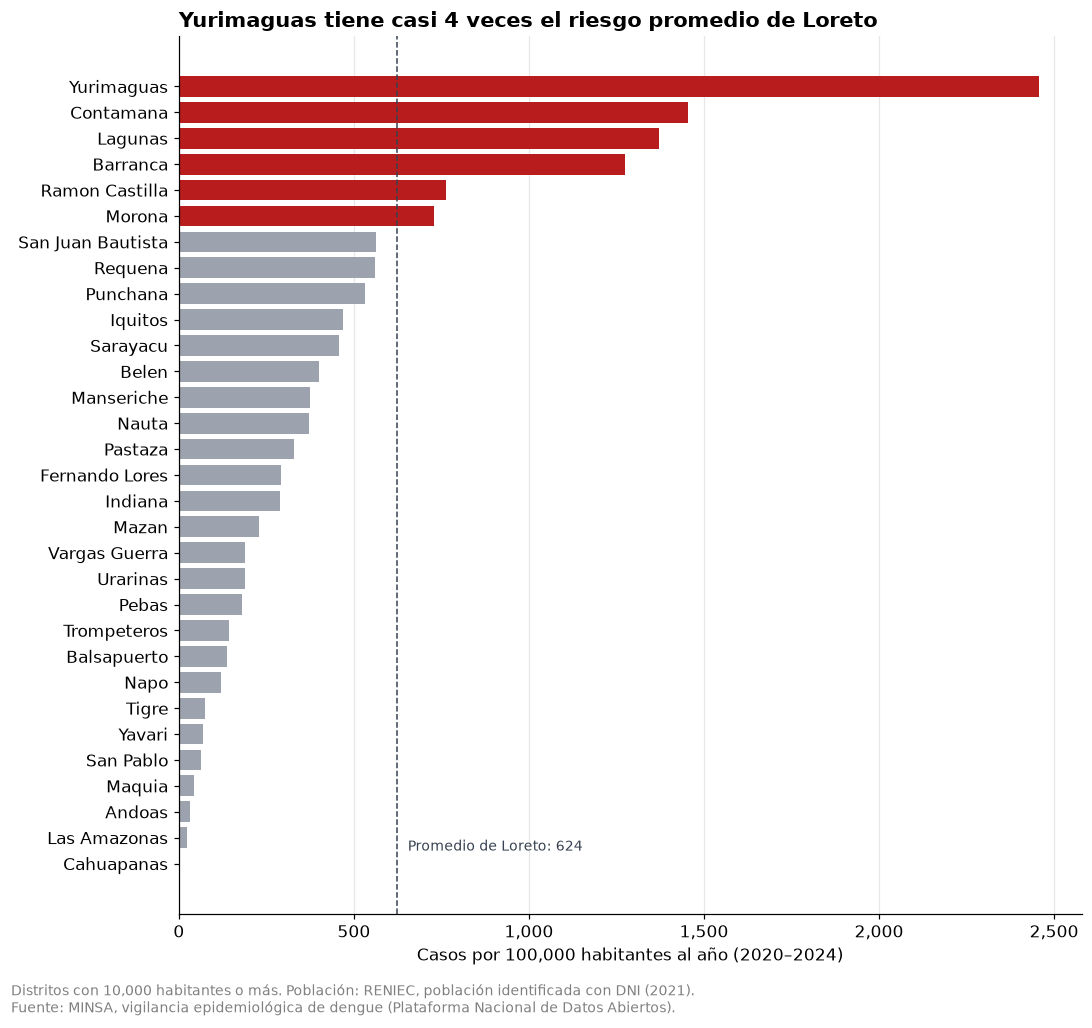

In [ ]:
inc = consulta("""
WITH casos_distrito AS (
    SELECT ubigeo, COUNT(*) AS casos
    FROM casos
    WHERE ano BETWEEN 2020 AND 2024
    GROUP BY ubigeo
)
SELECT
    p.distrito,
    p.poblacion,
    COALESCE(c.casos, 0) AS casos,
    COALESCE(c.casos, 0) * 100000.0 / p.poblacion / 5 AS incidencia
FROM poblacion AS p
LEFT JOIN casos_distrito AS c
    ON p.ubigeo = c.ubigeo
""")

# Promedio de Loreto: con TODOS los distritos, antes de filtrar
promedio_loreto = inc["casos"].sum() * 100000 / inc["poblacion"].sum() / 5

# Solo distritos grandes, ordenados de menor a mayor (barh dibuja de abajo hacia arriba)
grandes = inc[inc["poblacion"] >= 10000].sort_values("incidencia")
colores = [COLOR_DESTACADO if v > promedio_loreto else COLOR_BASE for v in grandes["incidencia"]]

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(grandes["distrito"].str.title(), grandes["incidencia"], color=colores)

# Línea del promedio
ax.axvline(promedio_loreto, color="#374151", linestyle="--", linewidth=1)
ax.text(promedio_loreto + 30, 0.5, f"Promedio de Loreto: {promedio_loreto:,.0f}",
        fontsize=9, color="#374151")

ax.set_title("Yurimaguas tiene casi 4 veces el riesgo promedio de Loreto",
            loc="left", fontsize=14, fontweight="bold")
ax.set_xlabel("Casos por 100,000 habitantes al año (2020–2024)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

fig.text(0.01, -0.03,
        "Distritos con 10,000 habitantes o más. Población: RENIEC, población identificada con DNI (2021).\n" + FUENTE,
        fontsize=9, color="gray")
plt.tight_layout()
fig.savefig("../figures/03_incidencia_distrito.png", dpi=150, bbox_inches="tight")
plt.show()

> 🔎 **Qué muestra el gráfico:**
> - **6 distritos grandes superan el promedio de Loreto:** Yurimaguas, Contamana, Lagunas, Barranca, Ramón Castilla y Morona.
> - **Los cuatro distritos de la ciudad de Iquitos están por debajo del promedio**, aunque concentran la mayoría de los casos.
> - **Casi todos los distritos con mayor riesgo son pueblos y capitales a orillas de grandes ríos, fuera de Iquitos** (Huallaga, Ucayali, Marañón y Amazonas).
> - **Hipótesis (no comprobadas con estos datos):** el *Aedes aegypti* se cría en el agua almacenada de las zonas urbanas; los ríos y carreteras facilitan la llegada del virus; y estos pueblos tienen establecimientos de salud que notifican sus casos.
> - **Precaución:** son datos de vigilancia. Un distrito sin servicios de salud tendría *menos* casos registrados, no más; por eso los distritos sin casos, como Cahuapanas, no significan necesariamente que no haya dengue.